# Hackathon 1, statistics.

This project illustrates the statistics part of the course LEPL1109. In the first part of the project, you will study the mortality observed in Belgium. In the second part of the project, you try to predict the electricity consumption in Belgium using climate variables.

## Report content

•	Grades are granted to the members whose names are in the Jupyter notebook. If your name doesn’t appear on the top of the notebook, you’ll get a 0, even though you are in a group on Moodle.

•	The jupyter notebook must be compiled with printed results and next submitted via moodle. The absence of compiled results (or non-printed values) leads to a lower grade.

•	Do not comment your results directly into cells of code. Use instead a Markdown cell. 

•	"Dry" code or results not followed by a minimum of analysis / comments will be penalized.


## Report submission

•	Deadline, see moodle website. Submission after the deadline will not be accepted.

•	To submit your report, go to the section “Hackathon” on Moodle and the subsection “Remise Hackathon 1”. You can upload your work there. Once you are sure that it is your final version, click the button “Envoyer le devoir”. It is important that you don’t forget to click on this button ! 

•	Reports that have not been uploaded through Moodle will not be corrected.


## Names and Noma of participants:

Part. 1: Berger Arthur  7067 2400

Part. 2: Collignon Robin  4958 2400

Part. 3: Doucet Noah 4035 2400 

Part. 4: Michiels Romain  3583 2400

Part. 5:

Part. 6:

# Mortality and climate

In this section, we analyze the relationship between mortality, age groups, and seasons in Belgium using publicly available data from Statbel (see https://statbel.fgov.be/en/about-statbel/what-we-do/visualisations/mortality). The dataset contains the number of deaths recorded over time, disaggregated by age group and observed across different seasons. The objective is to study temporal patterns in mortality and assess the role of seasonal effects. 

## 1. Basic statistics

**1.1)** Load the dataset mortality_climate.csv. Convert the variables *season* and *CD_AGEGROUP* into a categorical variable. 

In [56]:
# Code here
%pip install pandas
%pip install matplotlib
%pip install numpy
%pip install scipy
%pip install statmodels.api
import pandas as pd


df = pd.read_csv("mortality_climate.csv", sep=',')
df["season"]=df["season"].astype("category")
df["CD_AGEGROUP"]=df["CD_AGEGROUP"].astype("category")


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
ERROR: Could not find a version that satisfies the requirement statmodels.api (from versions: none)

[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
ERROR: No matching distribution found for statmodels.api
Note: you may need to re

**1.2)** Plot the evolution of the number of deaths (*MS_NUM_DEATH*) with respect to age group. What do you observe?

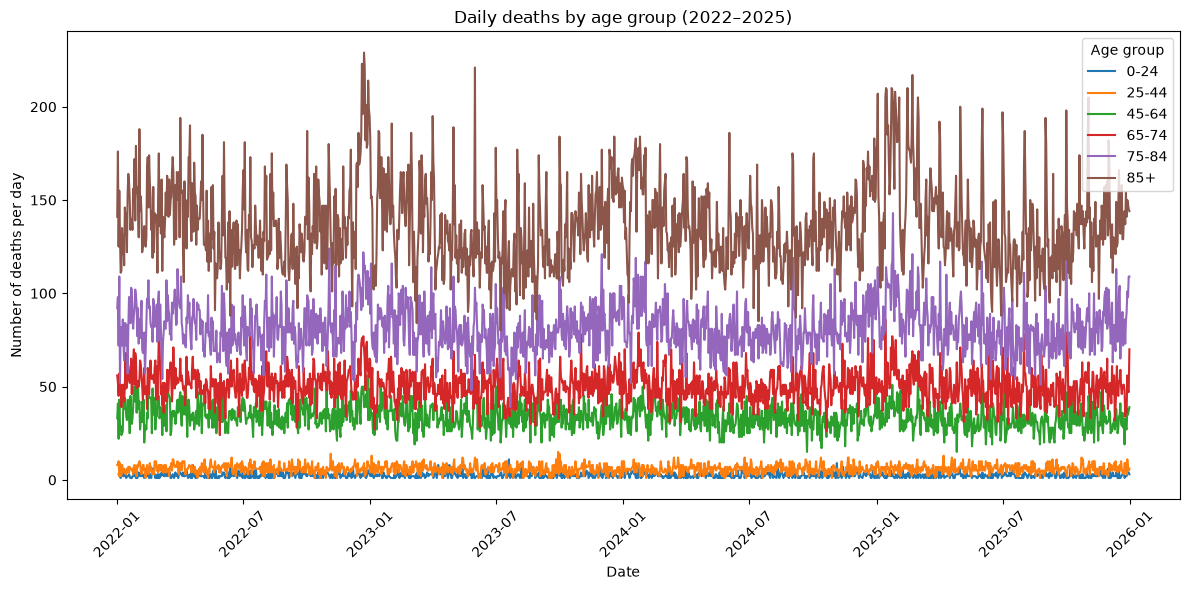

In [57]:
import matplotlib.pyplot as plt

# transformer la colonne "date" en type datetime
df["date"] = pd.to_datetime(df["date"])
#trie les différentes catégories d'age
ordre = ["0-24", "25-44", "45-64", "65-74", "75-84", "85+"]
#plot pour chaque catégorie le graphe du nombre de décès en fonction du temps
plt.figure(figsize=(12, 6))

for age in ordre:
    data = df[df["CD_AGEGROUP"] == age]
    data = data.sort_values("date")
    plt.plot(data["date"], data["MS_NUM_DEATH"], label=age)

plt.xlabel("Date")
plt.ylabel("Number of deaths per day")
plt.title("Daily deaths by age group (2022–2025)")

plt.legend(title="Age group", loc="upper right")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Comments:

Nous constatons différentes choses sur ce graphe. Premièrement, une augmentation du nombre de décès avec l'âge. En effet, la catégorie 85+ présente systématiquement un nombre de déces supérieur a toutes les autres catégories. A l'inverse, les catégories 0-24 et 25-44 présente un taux de déces relativement bas. Ensuite, le nombre de déces par catégorie est stable au court du temps malgré certaines fluctuations fortement présente dans la catégorie d'age la plus élevée. Ces pics sont particulierement éleve en janvier 2023 et 2025.
En conclusion, ce graphe met en évidence les fortes différences du nombre de déces en fonction de l'age ainsi que la possibilité de fluctuation plus marquée.

**1.3)** Do a scatter plot of the number of deaths (*MS_NUM_DEATH*) by age group.

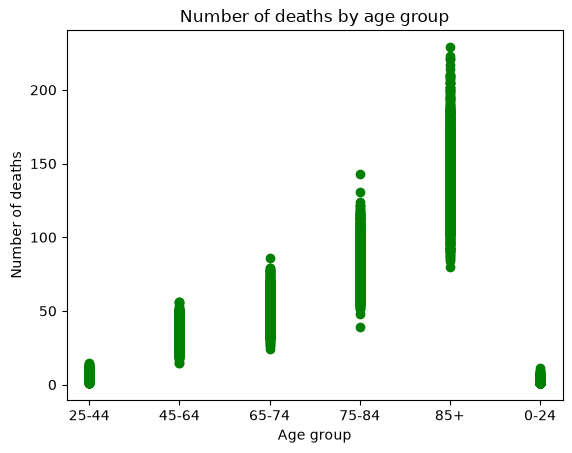

In [58]:
# Code here 
age = df["CD_AGEGROUP"]
deaths = df["MS_NUM_DEATH"]
ordre = ["0-24", "25-44", "45-64", "65-74", "75-84", "85+"]
df = df.sort_values("CD_AGEGROUP")
plt.scatter(age, deaths, color='g')

plt.xlabel("Age group")
plt.ylabel("Number of deaths")
plt.title("Number of deaths by age group")
plt.show()

Comments: 

  Nous constatons que le nombre de déces et l'écart type augmente avec l'âge. 

## 2. Fit of distributions

**2.1)** For the 45–64 age group and the winter season only, fit both a Poisson and a Negative Binomial distribution to the variable 'MS_NUM_DEATH' using a maximum likelihood approach. Plot histograms overlaid with the fitted probability mass functions. Compare the log-likelihoods and select the most appropriate distribution.

Poisson log-likelihood: -1219.3605439541716
Negative Binomial log-likelihood: -1206.5396787319285
n = 81.40149598216637 p = 0.6959336488619945


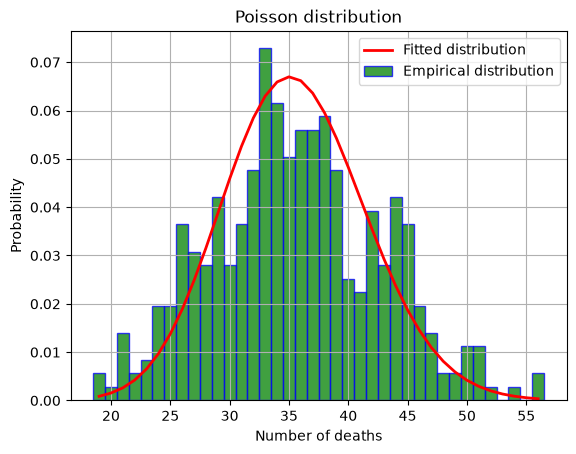

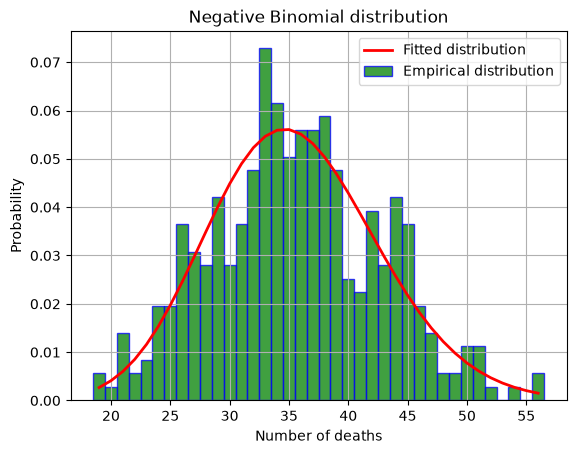

Poisson log-likelihood: -1219.3605439541716
Negative Binomial log-likelihood: -1206.5396787319285
Negative Binomial has the higher log-likelihood


In [59]:
#code ici

import scipy.stats as sc
from scipy.optimize import minimize
import numpy as np

# Selectionner les données pour l'âge 45-64 et la saison hiver
data = df[(df["season"].str.lower() == "winter") & (df["CD_AGEGROUP"] == "45-64")]
datn = data["MS_NUM_DEATH"].dropna().values

# Poisson distribution
lam = np.mean(datn)
ll_poisson = np.sum(sc.poisson.logpmf(datn, mu=lam))

print("Poisson log-likelihood:", ll_poisson)

# Negative Binomial distribution
def neg_log_likelihood(params):
    n, p = params
    return -np.sum(sc.nbinom.logpmf(datn, n, p))

result = minimize(neg_log_likelihood, [10, 0.5],
                  bounds=[(0.001, None), (0.001, 0.999)])

if not result.success:
    print("Warning:", result.message)

n, p = result.x
ll_nb = -result.fun

print("Negative Binomial log-likelihood:", ll_nb)
print("n =", n, "p =", p)

# Plot les graphes
x = np.arange(min(datn), max(datn) + 1)

fx_poisson = sc.poisson.pmf(x, mu=lam)
fx_nb = sc.nbinom.pmf(x, n, p)

plt.hist(datn, bins=np.arange(min(datn)-0.5, max(datn)+1.5),
         density=1, facecolor='g', alpha=0.75, edgecolor='b')
plt.plot(x, fx_poisson, 'r', lw=2)
plt.xlabel('Number of deaths')
plt.ylabel('Probability')
plt.title('Poisson distribution')
plt.legend(['Fitted distribution', 'Empirical distribution'])
plt.grid(True)
plt.show()

plt.hist(datn, bins=np.arange(min(datn)-0.5, max(datn)+1.5),
         density=1, facecolor='g', alpha=0.75, edgecolor='b')
plt.plot(x, fx_nb, 'r', lw=2)
plt.xlabel('Number of deaths')
plt.ylabel('Probability')
plt.title('Negative Binomial distribution')
plt.legend(['Fitted distribution', 'Empirical distribution'])
plt.grid(True)
plt.show()

# Compare log-likelihoods
print("Poisson log-likelihood:", ll_poisson)
print("Negative Binomial log-likelihood:", ll_nb)

if ll_poisson > ll_nb:
    print("Poisson has the higher log-likelihood")
else:
    print("Negative Binomial has the higher log-likelihood")



Comments: 

On constate que la binomiale négative donne une approximation plus précise car il a une vraissemblance plus élevée que celle par la distribution de poisson. En effet, on constate que la binomiale négative correspond mieux a la répartition expérimentale. Cela est fortement visbible pour les valeurs extrêmes.

# 3. Regression

We now aim to assess whether seasonality has an impact on the number of deaths. We consider the following linear model:
$$\log(Y_i) = \beta_0 + \beta_1 X^S_{i1} + \cdots + \beta_3 X^S_{i3} + \beta_4 X^{age}_{i1} + \cdots + \beta_8 X^{age}_{i5}  + \varepsilon_i.$$

where $Y_i$ denotes the number of deaths, $X^S_{ij}$ are dummy variables representing the different seasons, $X^{age}_{ij}$ are dummy variables representing the different age groups, and $\varepsilon_i \sim N(0, \sigma^2)$. 

**3.1)** Why is it more appropriate to use a linear regression on $\log(Y)$ rather than directly on $Y$?

Comments: 

Parce que 

**3.2)** Perform a linear regression of the number of deaths on the seasonal and group age covariates. Use the `OLS` function from the *statsmodels* package. Make sure to convert the variable *season* and *CD_AGEGROUP* into dummy variables before fitting the model.

Does seasonality have a significant impact on mortality? Is the mortality similar for each age group? 

In [60]:
# Code here
%pip install statsmodels
import statsmodels.api as sm

# On transforme en variables indicatrices
season_dum = pd.get_dummies(df["season"], drop_first=True, dtype=int)
agegroup_dum = pd.get_dummies(df["CD_AGEGROUP"], drop_first=True, dtype=int)

Y = df["MS_NUM_DEATH"]

X = pd.concat([season_dum, agegroup_dum], axis=1)
# On ajoute une constante (pour beta0)
Xm = sm.add_constant(X)

# Utilisation du modèle OLS comme demandé + fitting 
results = sm.OLS(Y, Xm).fit()

# Affichage des résultats
print(results.summary())


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
                            OLS Regression Results                            
Dep. Variable:           MS_NUM_DEATH   R-squared:                       0.942
Model:                            OLS   Adj. R-squared:                  0.942
Method:                 Least Squares   F-statistic:                 1.739e+04
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:00:44   Log-Likelihood:                -33322.
No. Observations:                8625   AIC:                         6.666e+04
Df Residuals:                    8616   BIC:                         6.673e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err 

Comments: 

## 4. Hypothesis test 

We now investigate whether mortality decreases over time by comparing mortality in summer in 2022 and 2025. To this end, we aim to perform the following hypothesis test:

$$
H_0 : \mu_{2022} = \mu_{2025},
$$

$$
H_1 : \mu_{2022} \neq \mu_{2025}.
$$

**4.1)** Create two subsets of the original dataset corresponding to the years 2022 and 2025, respectively.

In [62]:
df_2022 = df[df["date"].dt.year == 2022]
df_2025 = df[df["date"].dt.year == 2025]


**4.2)** For the 85+ age group, perform a Student’s t-test to compare mortality between 2022 and 2025 **in summer**. Check whether the assumptions required to apply this test are satisfied.

In [63]:
import scipy.stats as sc
import numpy as np

mortality_22 = df_2022[(df_2022["CD_AGEGROUP"].eq("85+")) & (df_2022["season"].eq("summer"))]["MS_NUM_DEATH"].to_numpy()
mortality_25 = df_2025[(df_2025["CD_AGEGROUP"].eq("85+")) & (df_2025["season"].eq("summer"))]["MS_NUM_DEATH"].to_numpy()

n22 = len(mortality_22)
n25 = len(mortality_25)
Xb22 = np.mean(mortality_22)
Xb25 = np.mean(mortality_25)
S22 = np.std(mortality_22, ddof=1)
S25 = np.std(mortality_25, ddof=1)

Spool = np.sqrt(((n22-1)*(S22**2) + ((n25-1)*(S25**2))) / (n22 + n25 - 2))
Tx    = (Xb22 - Xb25)/(Spool*np.sqrt(1/n22+1/n25))

#H0
pval = 2*sc.t.cdf(-np.abs(Tx),df=n22+n25-2)
print("p")
print([pval])
if(pval > 0.05): print("H0 s'applique, il n'y a pas assez de différence")

#H1
alpha = 0.05
t_l   = sc.t.ppf(q=alpha/2, df=n22+n25-2)
t_u   = sc.t.ppf(q=1-alpha/2, df=n22+n25-2)

print("t" + " t_lower" + " t_upper")
print([Tx, t_l, t_u])

#confidence interval alpha = 0.05
diff = Xb22 - Xb25
term = t_u*Spool*np.sqrt(1/n22+1/n25)
print("différence des moyennes (Xb2022 - Xb2025) = ", diff)
print("intervale de confidence (a=0.05)")
print([diff - term, diff + term])

p
[np.float64(0.042505762212459004)]
t t_lower t_upper
[np.float64(2.0425744211253742), np.float64(-1.972800113995442), np.float64(1.9728001139954416)]
différence des moyennes (Xb2022 - Xb2025) =  5.9787234042553195
intervale de confidence (a=0.05)
[np.float64(0.20423308876236046), np.float64(11.753213719748278)]


Comments:

On a bien une indépendence des X et Y, on considère que chaque mort est indépendente l'une de l'autre. Néanmoins, la courbe ne suit pas clairement une normale comme le veut l'hypothèse comme on peut le voir aux exercices 1.2, 1.3. Comme la p-valeur est en dessous de 0,05 on a que l'hypothèse H1 est la bonne, donc mu1 différent de mu2. On voit au print que la moyenne est plus grande en 2022 qu'en 2025. Elle descend bien avec le temps. L'intervalle de confidence à 95% est entre 0.2 et 11.75 décès par jour de différence. Comme cet intervalle ne contient pas 0, on reconfirme bien la statistique plus élevée en 2022 qu'en 2025. A prendre avec des pincettes au vu des hypothèses pas pleinement vérifiées.

**4.3)** Explain what the Wilcoxon test is. Why could it be relevant in our setting?

Comments: 

Le test de Wilcoxon est un test statistique qui compare deux variables aléatoires I.I.D sans avoir le besoin comme le Student's t d'une normalité de la distribution. Ce test est moins demandant en hypothèses. Il compare la position des données dans l'ordre des décès à la place des moyennes (student's t). Ce test est un bon test complémentaire pour comparer les deux années, sous des hypothèses mieux satisfaites.

**4.4)** For the 85+ age group, perform a Wilcoxon test to compare mortality between 2022 and 2025 **in summer**. What do you conclude?

In [64]:
U_wilcoxon, pval_wilcoxon = sc.mannwhitneyu(mortality_22, mortality_25)
print("U " + "p_val")
print([U_wilcoxon, pval_wilcoxon])

#H0
if(pval_wilcoxon > 0.05): print("H0 s'applique, il n'y a pas assez de différence")

U p_val
[np.float64(5555.0), np.float64(0.0023094915928322237)]


Comments:

Le test de Wilcoxon renforce la validité de notre test précédent car la p-valeur = 0.0023 est bien en dessous de la valeur significative 0.05.

**4.5)** Perform the Wilcoxon test but now for the 25–44 age group and the **summer**. What do you conclude in this case?

In [65]:
mortality_25_44_summer_22 = df_2022[(df_2022["CD_AGEGROUP"].eq("25-44")) & (df_2022["season"].eq("summer"))]["MS_NUM_DEATH"].to_numpy()
mortality_25_44_summer_25 = df_2025[(df_2025["CD_AGEGROUP"].eq("25-44")) & (df_2025["season"].eq("summer"))]["MS_NUM_DEATH"].to_numpy()

U_wilcoxon, pval_wilcoxon = sc.mannwhitneyu(mortality_25_44_summer_22, mortality_25_44_summer_25)
print("U " + "p_val")
print([U_wilcoxon, pval_wilcoxon])

#H0
if(pval_wilcoxon > 0.05): print("H0 s'applique, il n'y a pas assez de différence")

U p_val
[np.float64(4651.5), np.float64(0.5285373504458225)]
H0 s'applique, il n'y a pas assez de différence


Comments: 

On remarque ici que la p-valeur = 0.53 n'est pas en desous de la valeur significative 0.05. Ce test nous dit donc que l'hypothèse H1 n'est pas assez probable et que l'on utilise donc l'hypothèse H0. Les moyennes de 2022 et 2025 sont les mêmes pour le groupe d'âge 25-44ans en été.

# Electricity Consumption and Climate

In this section, we aim to predict electricity consumption using past consumption values and climatic variables. We rely on data provided by ELIA (see https://opendata.elia.be/explore/dataset/ods003/information/?sort=datetime), which records total electricity consumption in Belgium at a 15-minute frequency, and meteorological data from the Royal Meteorological Institute (IRM) (see https://www.meteo.be/fr/services/donnees), which provides daily average temperature observations over Belgium.

The goal is to build a predictive model for electricity demand based on its recent history and weather conditions. From a practical perspective, such forecasting is highly relevant for energy providers and grid operators, as accurately anticipating electricity demand one week ahead helps optimize production planning, ensure grid stability, and reduce operational costs.

## 5. Forecasting 

The goal is to predict electricity consumption at time $t$ using its past values and climate features. Let $Y_t$ denote electricity consumption at time $t$. We consider the following regression model:

$$Y_t = \beta_0 + \beta_1 Y_{t-7Days} + \beta_2 \bar{T}_{t-7Days} + \beta_3 \bar{T}_{t-7Days}^2 + \varepsilon_t,$$

where $Y_{t-7Days}$ denotes electricity consumption observed 7 days earlier, $\bar{T}_{t-7Days}$ is the average temperature observed 7 days earlier$^1$, and $\varepsilon_t \sim \mathcal{N}(0,\sigma^2)$ is an error term.

$^1$ The average temperature is measured at a daily frequency; therefore, $\bar{T}_{t-7Days}$ is constant for all time points $t$ within the same day.

**5.1)** Load the dataset *electricity_climate.csv* and construct the dataset required to perform the regression.

**Warning:** the data are observed at 15-minute intervals.

To build the regression dataset, each row must contain:
- electricity consumption at time $t$: $Y_t$,
- electricity consumption at time $t - 7$ days: $Y_{t-7Days}$,
- temperature at time $t - 7$ days: $\bar{T}_{t-7Days}$,
- the squared temperature at time $t - 7$ days: $\bar{T}_{t-7Days}^2$.

In [51]:
# Code here 
df=pd.read_csv("electricity_climate.csv", sep=',')
df["Y"]=df["Consumption"]
df["Y_lag7"]=df["Consumption"].shift(67)
df["T_lag7"]=df["temp_avg_sq"].shift(67)
df["T_lag7_squared"]=df["temp_avg_sq"].shift(67)**2
data=df[["Y","Y_lag7","T_lag7","T_lag7_squared"]].dropna()

**5.2)** Split the dataset into a training set (first 75%) and a test set (last 25%).  Use the `OLS` function from the *statsmodels* package to fit linear regression model using only $Y_{t-7Days}$ as explanatory variable.

Analyze the regression output, discuss the statistical significance and performance of the model.

In [52]:
# Code here 
import statsmodels.api as sm

n = int(len(data)*0.75)
train = data.iloc[:n]
test = data.iloc[n:]

X = sm.add_constant(train["Y_lag7"])
Y = train["Y"]

# Régression
model = sm.OLS(Y, X).fit()
print(model.summary())

# Prédictions
X_test = sm.add_constant(test["Y_lag7"])
Y_pred = model.predict(X_test)


                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.220
Model:                            OLS   Adj. R-squared:                  0.220
Method:                 Least Squares   F-statistic:                 8.331e+04
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:59:52   Log-Likelihood:            -2.5337e+06
No. Observations:              295235   AIC:                         5.067e+06
Df Residuals:                  295233   BIC:                         5.067e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       4405.1998     13.726    320.933      0.0

Comments:

**5.3)** Repeat the regression by including the climate variables in the model.

Are the climate variables statistically significant in explaining electricity consumption 7 days ahead?

In [53]:
# Code here
import statsmodels.api as sm

n = int(len(data)*0.75)
train2 = data.iloc[:n]
test2 = data.iloc[n:]

X2 = sm.add_constant(train2[["Y_lag7", "T_lag7", "T_lag7_squared"]])
Y2 = train2["Y"]

model2 = sm.OLS(Y2, X2).fit()
print(model2.summary())

X_test2 = sm.add_constant(test2[["Y_lag7", "T_lag7", "T_lag7_squared"]])
Y_pred2 = model2.predict(X_test2)


                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.285
Model:                            OLS   Adj. R-squared:                  0.285
Method:                 Least Squares   F-statistic:                 3.930e+04
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:59:55   Log-Likelihood:            -2.5208e+06
No. Observations:              295235   AIC:                         5.042e+06
Df Residuals:                  295231   BIC:                         5.042e+06
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const           6086.5851     16.658    365.

Comments: 

**5.4)** Compute the MAE and RMSE on the test set for both models: with and without climate variables.

Does the inclusion of climate variables improve the predictive performance of the model?

In [54]:
# Code here 
mae=(abs(test["Y"]-Y_pred)).mean()
mse=((test["Y"]-Y_pred)**2).mean()

mae2=(abs(test["Y"]-Y_pred2)).mean()
mse2=((test["Y"]-Y_pred2)**2).mean()
print("MAE model 1:", mae)
print("MSE model 1:", mse)
print("MAE model 2:", mae2)
print("MSE model 2:", mse2)

MAE model 1: 1458.7355151927106
MSE model 1: 3814790.0043450193
MAE model 2: 1437.0525226057425
MSE model 2: 3687370.2995200027


Comments: 

**5.5)** For the model including climate variables, plot the predicted electricity consumption versus the true consumption on the test set. Then, produce a second plot focusing only on the first 7 days of the test set.

<Figure size 1200x500 with 0 Axes>

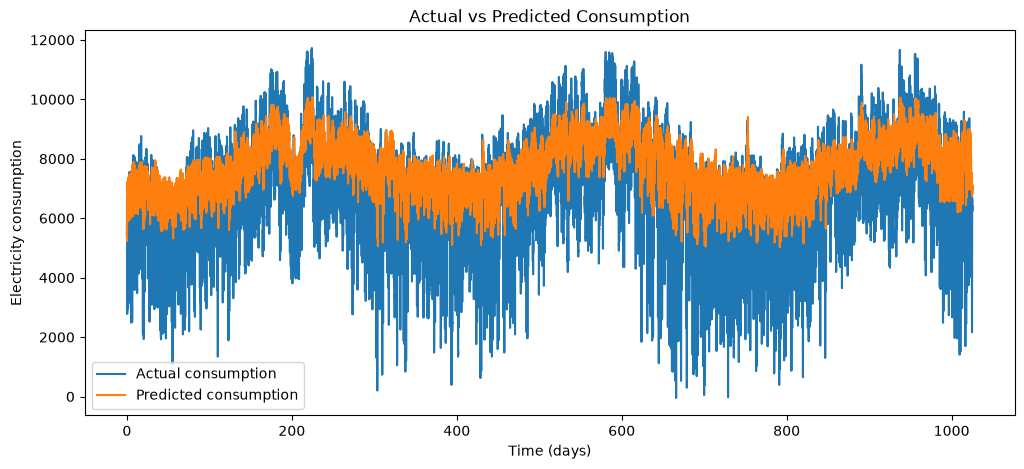

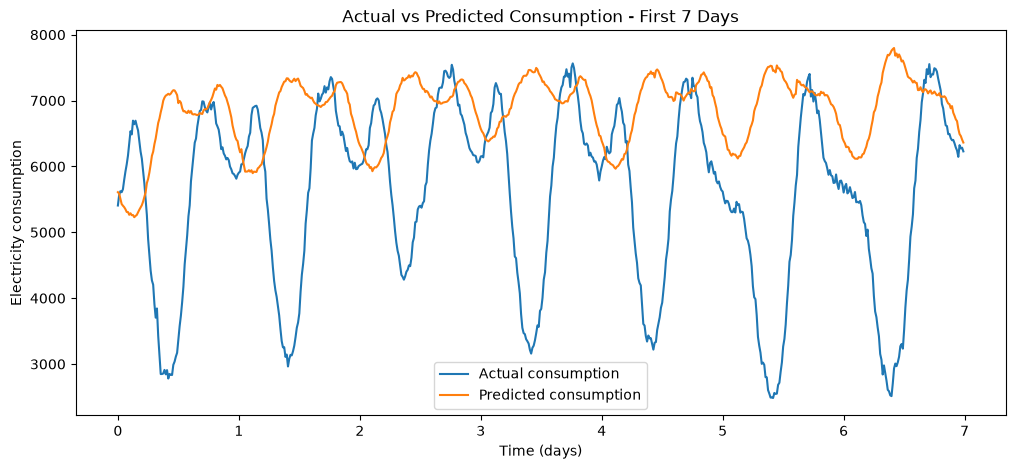

In [55]:
# Code here 
plt.figure(figsize=(12, 5))

time = np.arange(len(test["Y"])) / 96

plt.figure(figsize=(12, 5))

plt.plot(time, test["Y"].values, label="Actual consumption")
plt.plot(time, Y_pred2.values, label="Predicted consumption")

plt.xlabel("Time (days)")
plt.ylabel("Electricity consumption")
plt.title("Actual vs Predicted Consumption")
plt.legend()
plt.show()


plt.figure(figsize=(12, 5))

plt.plot(time[:672],test["Y"].values[:672], label="Actual consumption")
plt.plot(time[:672],Y_pred2.values[:672], label="Predicted consumption")

plt.xlabel("Time (days)")
plt.ylabel("Electricity consumption")
plt.title("Actual vs Predicted Consumption - First 7 Days")
plt.legend()
plt.show()

Comments: